# PC-FNO3D v7 — Reconstruction 3D du vent (projet ANEO)

**v7** = nouvel entrainement (≈ 5 h sur A100 + 45 min de cache), chaque changement vise une faiblesse mesuree en v6 :

| Changement | Faiblesse visee (v6) |
|---|---|
| Surface : moyenne des capteurs par bloc 2×2 (tous les capteurs, au lieu d'1 sur 4) | bruit de mesure, RMSE (DSO1) |
| Branche convolutive locale 3×3×3 dans chaque couche de Fourier | details < 1.6 km perdus (rugosite 0.82, DSO3), RMSE |
| Moyenne exponentielle des poids (EMA) pour la validation et les checkpoints | fluctuations de validation, RMSE |
| Validation sur les instants synoptiques (repartis sur les jours) | selection du checkpoint bruitee |
| Poids des gradients 0.15 des l'entrainement, sortie fp32 | champs trop lisses, plancher de masse |
| BLOC 10c : moyenne de predictions (test-time ensembling) | erreur aleatoire residuelle |

Les resultats v6 ne sont pas touches (dossiers `aneo_cache_v7` et `aneo_fno3d_runs/v7`).

| Bloc | Contenu |
|---|---|
| 0 | Montage du Drive, imports, GPU |
| 1 | Configuration |
| 2 | Grille statique, masques, operateurs |
| 3 | Construction du cache de tenseurs (une seule fois) |
| 4 | Controle de la verite terrain (residu de masse, condition au sol) |
| 5 | Normalisation (jours d'entrainement uniquement) |
| 6 | Dataset et DataLoaders (masquage des capteurs) |
| 7 | Modele PC-FNO3D |
| 8 | Loss physique |
| 9 | Entrainement (reprise automatique) |
| 9b | Raffinement oriente DSO (selection du checkpoint sur les DSO) |
| 10 | Evaluation test et DSO (metriques globales par niveau, DSO1 a DSO5) |
| 10c | Moyenne de predictions (reduction de l'erreur sans reentrainement) |
| 11 | Figures |
| 12 | Reconstruction 3D d'un instant (carte, coupe, export) |
| 12 | Reconstruction 3D a partir des mesures de surface (export CSV / NPZ, coupe verticale) |

## BLOC 0 — Montage du Drive, imports, GPU

In [16]:
# BLOC 0 — Montage du Drive, imports, GPU
import os, json, math, time, random, gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import gaussian_filter, binary_erosion
import pyarrow.csv as pacsv

TEST_MODE = os.environ.get("ANEO_TEST") == "1"      # validation locale sur mini-dataset

if not TEST_MODE:
    from google.colab import drive
    drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
if device.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} Go")
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("BLOC 0 OK")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device : cuda
GPU    : NVIDIA A100-SXM4-80GB
VRAM   : 85.1 Go
BLOC 0 OK


## BLOC 1 — Configuration

In [17]:
# BLOC 1 — Configuration
# Securite : si le BLOC 0 n'a pas ete execute (redemarrage de session), on recharge l'essentiel.
if "TEST_MODE" not in globals():
    import os, json, math, time, random, gc
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import torch
    TEST_MODE = os.environ.get("ANEO_TEST") == "1"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("BLOC 0 non execute : relance-le pour monter le Drive et charger tous les imports.")

if TEST_MODE:
    DATA_DIR = Path(os.environ["ANEO_DATA"])
    CACHE_DIR = Path(os.environ["ANEO_CACHE"])
    RUN_DIR = Path(os.environ["ANEO_RUN"])
else:
    DATA_DIR = Path("/content/drive/MyDrive/aneo_dataset_3d_v2")   # dataset genere v2 (csv.gz)
    CACHE_DIR = Path("/content/aneo_cache_v7")                      # tenseurs .npy (disque local)
    RUN_DIR = Path("/content/drive/MyDrive/aneo_fno3d_runs/v7")     # checkpoints, resultats, figures
for d in (CACHE_DIR, RUN_DIR, RUN_DIR / "figures"):
    d.mkdir(parents=True, exist_ok=True)

# Cache persistant sur le Drive (v7 : surface moyennee par blocs 2x2, incompatible avec le cache v6)
import shutil
CACHE_DRIVE = None if TEST_MODE else Path("/content/drive/MyDrive/aneo_cache_v7")

if CACHE_DRIVE is not None and (CACHE_DRIVE / "index.csv").exists() and not (CACHE_DIR / "index.csv").exists():
    print("Copie du cache depuis le Drive vers le disque local...")
    t0 = time.time()
    shutil.copytree(CACHE_DRIVE, CACHE_DIR, dirs_exist_ok=True)
    print(f"Cache copie en {(time.time() - t0) / 60:.1f} min")

with open(DATA_DIR / "meta.json", encoding="utf-8") as f:
    META = json.load(f)
with open(DATA_DIR / "split_days.json", encoding="utf-8") as f:
    SPLIT = json.load(f)

# Geometrie (lue depuis meta.json du generateur)
NX_S, NY_S = META["grille_surface"]["nx"], META["grille_surface"]["ny"]
DX_S = float(META["grille_surface"]["dx_m"])
DY_S = float(META["grille_surface"]["dy_m"])
STRIDE = META["noeuds_3d"]["stride"]
NX, NY = NX_S // STRIDE, NY_S // STRIDE                     # grille du modele (100 m)
DX, DY = DX_S * STRIDE, DY_S * STRIDE
Z_LEVELS = np.array(META["noeuds_3d"]["z_levels_asl_m"], dtype=np.float64)
NZ = len(Z_LEVELS)
NODE_ID_START = META["noeuds_3d"]["point_id_debut"]
TERRAIN_SMOOTH_M = 300.0     # meme lissage que le generateur pour la condition au sol

# Modele
WIDTH = 48
MODES = (6, 32, 32)          # (z, y, x) : plus de modes pour les structures fines (DSO3)
N_LAYERS = 4
LOCAL_CONV = True            # branche convolutive locale 3x3x3 (details fins, DSO3)
POOL_SURFACE = True          # surface : moyenne des capteurs par bloc 2x2 au lieu d'1 capteur sur 4
PROJ_HIDDEN = 128            # largeur de la tete de projection
PAD = (4, 8, 8)              # rembourrage (z, y, x) : limite la periodicite de la FFT

# Entrainement
EPOCHS = 140
STEPS_PER_EPOCH = 400        # instants tires au hasard par epoque
VAL_SAMPLES = 64             # sous-ensemble fixe de validation
BATCH_SIZE = 1
ACCUM_STEPS = 2
LR = 1e-3
WEIGHT_DECAY = 1e-4
WARMUP_PHYS_EPOCHS = 10      # montee progressive des termes physiques
NUM_WORKERS = 4
EMA_DECAY = 0.999             # moyenne exponentielle des poids (modele evalue et sauvegarde)

# Masquage des capteurs (entree)
KEEP_TRAIN = (0.2, 1.0)      # fraction de capteurs visibles, tiree a chaque echantillon
KEEP_EVAL = 0.5              # fraction fixe en validation / test

# Poids de la loss
LAMBDA_MASS = 1.0            # applique a L_mass / MASS_REF
MASS_REF = 5e-7              # echelle du terme de masse dans la loss (DSO2 avec marge)
LAMBDA_BC = 0.1
LAMBDA_SMOOTH = 0.0          # donnees deja lisses : terme desactive par defaut
LAMBDA_GRAD = 0.15           # loss sur les gradients horizontaux (corrige le lissage, DSO3 et w)
W_WEIGHT = 1.0               # poids de w dans L_data
W_LEVEL_MAX = 25.0           # plafond du poids de w par niveau (w est tres faible en altitude)
DSO_R2_ALL = 0.95            # objectif : R2 global >= 0.95 pour u, v ET w a chaque niveau

# Seuils des DSO
DSO1_RMSE = 0.5              # m/s, u et v, a chaque niveau
DSO1_R2 = 0.95               # R2 global par niveau
DSO2_RMS = 1e-4              # kg.m-3.s-1, RMS du residu de continuite
DSO3_RANGE = (0.0, 1.1)      # DSO3 : pas de bruit artificiel (rugosite <= 1.1 x verite)
DSO4_TIME = 1.0              # s par instant
DSO5_RMSE = 0.7              # m/s avec 25 % des capteurs
MIN_LEVEL_COVER = 0.05       # niveaux couvrant moins de 5 % du domaine exclus des DSO par niveau
F_CORIOLIS = 8.57e-5         # s-1, latitude ~36 N

if TEST_MODE:
    WIDTH, MODES, N_LAYERS, PAD, PROJ_HIDDEN = 4, (4, 8, 8), 2, (2, 4, 4), 4
    EPOCHS, STEPS_PER_EPOCH, VAL_SAMPLES, NUM_WORKERS = 2, 3, 2, 0
    WARMUP_PHYS_EPOCHS = 1

print(f"Grille modele : NZ={NZ} x NY={NY} x NX={NX} (dx={DX:.0f} m)")
print(f"Niveaux ASL   : {Z_LEVELS.tolist()}")
print(f"Split jours   : train={len(SPLIT['train_days'])} val={len(SPLIT['val_days'])} "
      f"test={len(SPLIT['test_days'])}")
print("BLOC 1 OK")

Grille modele : NZ=12 x NY=250 x NX=500 (dx=100 m)
Niveaux ASL   : [25.0, 50.0, 75.0, 100.0, 150.0, 200.0, 300.0, 400.0, 500.0, 650.0, 800.0, 1000.0]
Split jours   : train=70 val=15 test=15
BLOC 1 OK


## BLOC 2 — Grille statique, masques, operateurs

In [18]:
# BLOC 2 — Grille statique, masques, operateurs
grid = pd.read_csv(DATA_DIR / "aneo_grid_points.csv",
                   usecols=["point_id", "ix", "iy", "z_terrain_m", "z_rel_m", "z0_m",
                            "slope_deg", "aspect_deg"])

surf = grid[grid["point_id"] < NODE_ID_START].sort_values(["iy", "ix"]).reset_index(drop=True)
assert len(surf) == NX_S * NY_S, "Grille de surface incomplete"
nodes = grid[grid["point_id"] >= NODE_ID_START].reset_index(drop=True)

def s2d(col):
    return surf[col].values.reshape(NY_S, NX_S).astype(np.float64)

ZT_50 = s2d("z_terrain_m")
zt = ZT_50[::STRIDE, ::STRIDE]
z0 = np.maximum(s2d("z0_m")[::STRIDE, ::STRIDE], 1e-4)
slope = s2d("slope_deg")[::STRIDE, ::STRIDE]
aspect = np.radians(s2d("aspect_deg")[::STRIDE, ::STRIDE])
zrel_sensor = s2d("z_rel_m")[::STRIDE, ::STRIDE]

# point_id de surface -> indice plat (grille 50 m)
PID_TO_SURF = np.full(int(surf["point_id"].max()) + 1, -1, dtype=np.int64)
PID_TO_SURF[surf["point_id"].values] = np.arange(len(surf))

# noeud 3D -> indice plat (NZ, NY, NX)
z_abs_nodes = nodes["z_terrain_m"].values + nodes["z_rel_m"].values
k_nodes = np.abs(z_abs_nodes[:, None] - Z_LEVELS[None, :]).argmin(axis=1)
j_nodes = nodes["iy"].values // STRIDE
i_nodes = nodes["ix"].values // STRIDE
NODE_FLAT = np.full(int(nodes["point_id"].max()) - NODE_ID_START + 1, -1, dtype=np.int64)
NODE_FLAT[nodes["point_id"].values - NODE_ID_START] = (k_nodes * NY + j_nodes) * NX + i_nodes

VALID = np.zeros(NZ * NY * NX, dtype=bool)
VALID[NODE_FLAT[NODE_FLAT >= 0]] = True
VALID = VALID.reshape(NZ, NY, NX)

# Masque du residu de masse : les deux niveaux valides ET les voisins horizontaux utilises
# par les differences centrees valides (sinon le sol, rempli de zeros, fausse la divergence).
cross = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool)
VALID_INTERIOR = np.stack([binary_erosion(VALID[k], structure=cross, border_value=1)
                           for k in range(NZ)])
MASS_MASK = VALID_INTERIOR[1:] & VALID_INTERIOR[:-1]

# Premier noeud valide de chaque colonne (condition cinematique au sol)
FIRST_VALID = VALID.copy()
FIRST_VALID[1:] &= ~VALID[:-1]

# Pente du relief vu par l'ecoulement (meme lissage que le generateur)
zt_flow = gaussian_filter(ZT_50, sigma=TERRAIN_SMOOTH_M / DX_S, mode="nearest")[::STRIDE, ::STRIDE]
DZT_DY, DZT_DX = np.gradient(zt_flow, DY, DX)

# Champs statiques d'entree (normalises a la main, ordres de grandeur O(1))
z_asl = np.broadcast_to(Z_LEVELS[:, None, None], (NZ, NY, NX))
z_agl = np.clip(z_asl - zt[None], 0.0, None)
logz0 = np.log(z0)
STATIC_2D = np.stack([
    zt / 500.0,
    (logz0 - logz0.mean()) / (logz0.std() + 1e-6),
    slope / 10.0,
    np.sin(aspect),
    np.cos(aspect),
    (zrel_sensor - 25.0) / 5.0,
]).astype(np.float32)
STATIC_3D = np.stack([z_asl / 1000.0, z_agl / 1000.0, VALID.astype(np.float64)]).astype(np.float32)

N_SURF = 7                                   # u, v, w, T, rho, RH, p
# Coordonnees centrees et altitude des capteurs (estimation du vent geostrophique)
XC = (np.arange(NX) * DX)[None, :].repeat(NY, 0) - (NX - 1) * DX / 2
YC = (np.arange(NY) * DY)[:, None].repeat(NX, 1) - (NY - 1) * DY / 2
Z_SENSOR = (ZT_50 + s2d("z_rel_m")).reshape(NY, STRIDE, NX, STRIDE).mean(axis=(1, 3)) if POOL_SURFACE \
    else zt + zrel_sensor

def pool_surface(S):
    """(8, NY_S*NX_S ou NY_S, NX_S) -> (8, NY, NX). Canaux 0-6 : variables, canal 7 : capteur disponible.
    POOL_SURFACE : moyenne des capteurs disponibles de chaque bloc STRIDE x STRIDE (tous les capteurs
    sont utilises et le bruit de mesure est reduit) ; sinon un capteur sur STRIDE**2."""
    S = S.reshape(8, NY_S, NX_S)
    if not POOL_SURFACE:
        return S[:, ::STRIDE, ::STRIDE].copy()
    m = (S[7] > 0.5).astype(np.float32).reshape(NY, STRIDE, NX, STRIDE)
    cnt = m.sum(axis=(1, 3))
    out = np.zeros((8, NY, NX), dtype=np.float32)
    for c in range(7):
        v = S[c].reshape(NY, STRIDE, NX, STRIDE)
        out[c] = np.where(cnt > 0, (v * m).sum(axis=(1, 3)) / np.maximum(cnt, 1.0), 0.0)
    out[7] = (cnt > 0).astype(np.float32)
    return out

N_TFEAT = 8                    # heure (2), jour de l'annee (2), vent geostrophique (2), vent thermique (2)
C_IN = N_SURF + 1 + STATIC_2D.shape[0] + STATIC_3D.shape[0] + N_TFEAT
print(f"Noeuds valides : {VALID.sum():,} / {VALID.size:,} "
      f"| masse : {MASS_MASK.sum():,} demi-niveaux | canaux d'entree : {C_IN}")

# Operateurs discrets identiques au generateur (np.gradient + demi-niveaux)
DZ_T = torch.tensor(np.diff(Z_LEVELS), dtype=torch.float32, device=device)

def grad1d(f, h, dim):
    """Differences centrees a l'interieur, decentrees aux bords (equivalent np.gradient)."""
    n = f.shape[dim]
    first = (f.narrow(dim, 1, 1) - f.narrow(dim, 0, 1)) / h
    inner = (f.narrow(dim, 2, n - 2) - f.narrow(dim, 0, n - 2)) / (2.0 * h)
    last = (f.narrow(dim, n - 1, 1) - f.narrow(dim, n - 2, 1)) / h
    return torch.cat([first, inner, last], dim=dim)

def mass_residual(rho, u, v, w):
    """r(k+1/2) = (rho w[k+1] - rho w[k]) / dz + 0.5 (D[k] + D[k+1]) ; tenseurs (B, NZ, NY, NX)."""
    d = grad1d(rho * u, DX, -1) + grad1d(rho * v, DY, -2)
    rw = rho * w
    return (rw[:, 1:] - rw[:, :-1]) / DZ_T[None, :, None, None] + 0.5 * (d[:, 1:] + d[:, :-1])

VALID_T = torch.from_numpy(VALID).to(device)
GRAD_MASK_X_T = torch.from_numpy(VALID[:, :, 1:] & VALID[:, :, :-1]).to(device)
GRAD_MASK_Y_T = torch.from_numpy(VALID[:, 1:, :] & VALID[:, :-1, :]).to(device)
MASS_MASK_T = torch.from_numpy(MASS_MASK).to(device)
FIRST_VALID_T = torch.from_numpy(FIRST_VALID).to(device)
DZT_DX_T = torch.tensor(DZT_DX, dtype=torch.float32, device=device)
DZT_DY_T = torch.tensor(DZT_DY, dtype=torch.float32, device=device)
STATIC_2D_T = torch.from_numpy(STATIC_2D).to(device)
STATIC_3D_T = torch.from_numpy(STATIC_3D).to(device)
del grid
gc.collect()
print("BLOC 2 OK")

Noeuds valides : 849,184 / 1,500,000 | masse : 710,909 demi-niveaux | canaux d'entree : 25
BLOC 2 OK


## BLOC 3 — Construction du cache de tenseurs (une seule fois)

In [19]:
# BLOC 3 — Construction du cache de tenseurs (une seule fois)
# Pour chaque instant :
#   <jour>_<HHMMSS>_S.npy : surface (8, NY, NX) = u, v, w, T, rho, RH, p, capteur_disponible
#   <jour>_<HHMMSS>_Y.npy : volume (4, NZ, NY, NX) = u, v, w, rho (0 sous le terrain)
READ_COLS = ["point_id", "timestamp_utc", "temperature_c", "air_density_kg_m3",
             "relative_humidity_pct", "pressure_pa", "wind_u_m_s", "wind_v_m_s",
             "wind_w_m_s", "mask_i_obs"]
SURF_VARS = ["wind_u_m_s", "wind_v_m_s", "wind_w_m_s", "temperature_c",
             "air_density_kg_m3", "relative_humidity_pct", "pressure_pa"]

def day_of(path):
    return int(path.name.split("_")[3])

def split_of(day):
    if day in SPLIT["train_days"]:
        return "train"
    if day in SPLIT["val_days"]:
        return "val"
    return "test"

def build_day(path):
    day = day_of(path)
    opts = pacsv.ConvertOptions(include_columns=READ_COLS,
                                column_types={"timestamp_utc": "string"})
    tbl = pacsv.read_csv(path, convert_options=opts)
    pid = tbl.column("point_id").to_numpy()
    ts = tbl.column("timestamp_utc").to_pandas()
    codes, uniq = pd.factorize(ts, sort=True)
    cols = {c: tbl.column(c).to_numpy().astype(np.float32) for c in READ_COLS[2:]}
    del tbl
    rows = []
    for c, stamp in enumerate(uniq):
        sel = np.nonzero(codes == c)[0]
        p = pid[sel]
        is_s = p < NODE_ID_START
        ps, pn = p[is_s], p[~is_s]
        sel_s, sel_n = sel[is_s], sel[~is_s]

        S = np.zeros((8, NY_S * NX_S), dtype=np.float32)
        flat = PID_TO_SURF[ps]
        for ci, var in enumerate(SURF_VARS):
            S[ci, flat] = cols[var][sel_s]
        S[7, flat] = cols["mask_i_obs"][sel_s]
        S = pool_surface(S)

        Y = np.zeros((4, NZ * NY * NX), dtype=np.float32)
        nflat = NODE_FLAT[pn - NODE_ID_START]
        for ci, var in enumerate(["wind_u_m_s", "wind_v_m_s", "wind_w_m_s", "air_density_kg_m3"]):
            Y[ci, nflat] = cols[var][sel_n]
        Y = Y.reshape(4, NZ, NY, NX)

        tstamp = pd.Timestamp(stamp)
        stem = f"{day:03d}_{tstamp.strftime('%H%M%S')}"
        np.save(CACHE_DIR / f"{stem}_S.npy", S)
        np.save(CACHE_DIR / f"{stem}_Y.npy", Y)
        rows.append({"stem": stem, "day": day, "timestamp": str(tstamp), "split": split_of(day),
                     "hour": tstamp.hour + tstamp.minute / 60 + tstamp.second / 3600,
                     "doy": tstamp.dayofyear})
    return rows

index_path = CACHE_DIR / "index.csv"
done_days = set(pd.read_csv(index_path)["day"]) if index_path.exists() else set()
day_files = sorted(DATA_DIR.glob("aneo_observations_day_*_multitime.csv*"))
day_files = [p for p in day_files if not p.name.endswith(".part")]
todo = [p for p in day_files if day_of(p) not in done_days]
print(f"Jours disponibles : {len(day_files)} | deja en cache : {len(done_days)} | a traiter : {len(todo)}")

t0 = time.time()
for n, path in enumerate(todo, 1):
    rows = build_day(path)
    df_new = pd.DataFrame(rows)
    df_new.to_csv(index_path, mode="a", header=not index_path.exists(), index=False)
    el = time.time() - t0
    print(f"  jour {day_of(path):03d} : {len(rows)} instants | {n}/{len(todo)} "
          f"| reste ~{el / n * (len(todo) - n) / 60:.0f} min")
    gc.collect()

INDEX = pd.read_csv(index_path).drop_duplicates("stem").sort_values("stem").reset_index(drop=True)
print(INDEX["split"].value_counts().to_dict())

# Sauvegarde du cache sur le Drive (uniquement les fichiers absents)
if CACHE_DRIVE is not None:
    CACHE_DRIVE.mkdir(parents=True, exist_ok=True)
    existing = {p_.name for p_ in CACHE_DRIVE.glob("*.npy")}
    new_files = [p_ for p_ in sorted(CACHE_DIR.glob("*.npy")) if p_.name not in existing]
    if new_files:
        print(f"Sauvegarde du cache sur le Drive : {len(new_files)} fichiers...")
        for p_ in new_files:
            shutil.copy2(p_, CACHE_DRIVE / p_.name)
    shutil.copy2(CACHE_DIR / "index.csv", CACHE_DRIVE / "index.csv")
print("BLOC 3 OK")

Jours disponibles : 100 | deja en cache : 100 | a traiter : 0
{'train': 696, 'test': 166, 'val': 138}
Sauvegarde du cache sur le Drive : 2000 fichiers...
BLOC 3 OK


## BLOC 4 — Controle de la verite terrain

In [20]:
# BLOC 4 — Controle de la verite terrain
# Le residu de masse et la condition au sol doivent etre ~0 sur les donnees : sinon la loss
# physique contredirait les donnees et DSO2 serait inatteignable.
def load_y(stem):
    return torch.from_numpy(np.load(CACHE_DIR / f"{stem}_Y.npy")).to(device)

checks = []
for stem in INDEX["stem"].sample(min(5, len(INDEX)), random_state=0):
    y = load_y(stem)[None]
    u, v, w, rho = y[:, 0], y[:, 1], y[:, 2], y[:, 3]
    r = mass_residual(rho, u, v, w)
    l_mass = (r[:, MASS_MASK_T] ** 2).mean().item()
    w_bc = u * DZT_DX_T + v * DZT_DY_T
    l_bc = ((w - w_bc)[:, FIRST_VALID_T] ** 2).mean().item()
    checks.append((stem, l_mass, l_bc))
    print(f"  {stem} : L_mass(verite) = {l_mass:.2e} | ecart condition sol = {l_bc:.2e} (m/s)^2")
assert max(c[1] for c in checks) < 1e-6, "La verite ne respecte pas la continuite : verifier le dataset"
print("BLOC 4 OK")

  100_030000 : L_mass(verite) = 6.09e-12 | ecart condition sol = 1.15e-09 (m/s)^2
  087_210000 : L_mass(verite) = 6.08e-12 | ecart condition sol = 1.15e-09 (m/s)^2
  026_180000 : L_mass(verite) = 5.88e-12 | ecart condition sol = 1.15e-09 (m/s)^2
  054_030000 : L_mass(verite) = 5.41e-12 | ecart condition sol = 1.14e-09 (m/s)^2
  066_180000 : L_mass(verite) = 5.56e-12 | ecart condition sol = 1.14e-09 (m/s)^2
BLOC 4 OK


## BLOC 5 — Normalisation (jours d'entrainement uniquement)

In [21]:
# BLOC 5 — Normalisation (jours d'entrainement uniquement)
stats_path = RUN_DIR / "norm_stats.json"
if stats_path.exists():
    with open(stats_path, encoding="utf-8") as f:
        NORM = json.load(f)
else:
    tr = INDEX[INDEX["split"] == "train"]["stem"]
    tr = tr.sample(min(200, len(tr)), random_state=0)
    s_sum = np.zeros(N_SURF); s_sq = np.zeros(N_SURF); s_n = 0
    y_sum = np.zeros(3); y_sq = np.zeros(3); y_n = 0
    for stem in tr:
        S = np.load(CACHE_DIR / f"{stem}_S.npy").astype(np.float64)
        m = S[7] > 0.5
        s_sum += S[:N_SURF, m].sum(axis=1); s_sq += (S[:N_SURF, m] ** 2).sum(axis=1); s_n += m.sum()
        Y = np.load(CACHE_DIR / f"{stem}_Y.npy").astype(np.float64)
        y_sum += Y[:3, VALID].sum(axis=1); y_sq += (Y[:3, VALID] ** 2).sum(axis=1); y_n += VALID.sum()
    s_mu = s_sum / s_n; s_sd = np.sqrt(np.maximum(s_sq / s_n - s_mu ** 2, 1e-12))
    y_mu = y_sum / y_n; y_sd = np.sqrt(np.maximum(y_sq / y_n - y_mu ** 2, 1e-12))
    NORM = {"surf_mu": s_mu.tolist(), "surf_sd": s_sd.tolist(),
            "y_mu": y_mu.tolist(), "y_sd": y_sd.tolist(), "surf_vars": SURF_VARS}
    with open(stats_path, "w", encoding="utf-8") as f:
        json.dump(NORM, f, indent=2)

if "w_level_sd" not in NORM:
    tr = INDEX[INDEX["split"] == "train"]["stem"]
    tr = tr.sample(min(200, len(tr)), random_state=0)
    wl_sum = np.zeros(NZ); wl_sq = np.zeros(NZ); wl_n = np.zeros(NZ)
    for stem in tr:
        Yw = np.load(CACHE_DIR / f"{stem}_Y.npy")[2].astype(np.float64)
        for k in range(NZ):
            vals = Yw[k][VALID[k]]
            wl_sum[k] += vals.sum(); wl_sq[k] += (vals ** 2).sum(); wl_n[k] += vals.size
    wl_n = np.maximum(wl_n, 1)
    NORM["w_level_sd"] = np.sqrt(np.maximum(wl_sq / wl_n - (wl_sum / wl_n) ** 2, 1e-12)).tolist()
    with open(stats_path, "w", encoding="utf-8") as f:
        json.dump(NORM, f, indent=2)

SURF_MU = torch.tensor(NORM["surf_mu"], dtype=torch.float32, device=device)[:, None, None]
SURF_SD = torch.tensor(NORM["surf_sd"], dtype=torch.float32, device=device)[:, None, None]
Y_MU = torch.tensor(NORM["y_mu"], dtype=torch.float32, device=device)
Y_SD = torch.tensor(NORM["y_sd"], dtype=torch.float32, device=device)
# poids de w par niveau : chaque niveau compte selon sa propre variabilite (sinon w en altitude,
# tres faible, est neglige par la loss et son R2 chute)
W_LEVEL_SD = torch.tensor(NORM["w_level_sd"], dtype=torch.float32, device=device)
W_LEVEL_W = torch.clamp((Y_SD[2] / W_LEVEL_SD) ** 2, 1.0, W_LEVEL_MAX)
print("Poids de w par niveau :", np.round(W_LEVEL_W.cpu().numpy(), 2))
print("Cible  mu :", np.round(NORM["y_mu"], 3), " sd :", np.round(NORM["y_sd"], 3))
print("BLOC 5 OK")

Poids de w par niveau : [25.    7.07  4.26  2.93  1.37  1.    1.    1.    1.    1.48  2.04  2.43]
Cible  mu : [-1.026  0.429 -0.007]  sd : [8.519 8.389 0.282]
BLOC 5 OK


## BLOC 6 — Dataset, DataLoaders, assemblage de l'entree

In [22]:
# BLOC 6 — Dataset, DataLoaders, assemblage de l'entree
def geostrophic_from_surface(S, sensor):
    """
    Vent geostrophique estime a partir des capteurs visibles :
    pression reduite au niveau de la mer, plan ajuste par moindres carres, equilibre geostrophique
    ug = -(1 / rho f) dp/dy ; vg = (1 / rho f) dp/dx.
    """
    m = sensor
    if m.sum() < 100:
        return 0.0, 0.0
    p = S[6][m].astype(np.float64)
    t_k = S[3][m].astype(np.float64) + 273.15
    z = Z_SENSOR[m]
    p_sl = p * np.exp(9.80665 * z / (287.05 * (t_k + 0.5 * 0.0065 * z)))
    A = np.stack([np.ones(m.sum()), XC[m], YC[m]], axis=1)
    coef, *_ = np.linalg.lstsq(A, p_sl, rcond=None)
    rho = float(S[4][m].mean())
    return -coef[2] / (rho * F_CORIOLIS), coef[1] / (rho * F_CORIOLIS)

def thermal_wind_from_surface(S, sensor):
    """
    Vent thermique (variation du vent geostrophique avec l'altitude, en s-1) estime a partir
    du gradient horizontal de temperature des capteurs visibles, ramenee au niveau de la mer :
    d(ug, vg)/dz = (g / (f T)) * (-dT/dy, dT/dx).
    """
    m = sensor
    if m.sum() < 100:
        return 0.0, 0.0
    t_red = S[3][m].astype(np.float64) + 0.0065 * Z_SENSOR[m]
    A = np.stack([np.ones(m.sum()), XC[m], YC[m]], axis=1)
    coef, *_ = np.linalg.lstsq(A, t_red, rcond=None)
    k = 9.80665 / (F_CORIOLIS * (float(t_red.mean()) + 273.15))
    return -k * coef[2], k * coef[1]

def time_geo_features(S, sensor, hour, doy):
    ug, vg = geostrophic_from_surface(S, sensor)
    su, sv = thermal_wind_from_surface(S, sensor)
    return np.array([math.sin(2 * math.pi * hour / 24), math.cos(2 * math.pi * hour / 24),
                     math.sin(2 * math.pi * doy / 365), math.cos(2 * math.pi * doy / 365),
                     ug / 10.0, vg / 10.0, su * 200.0, sv * 200.0], dtype=np.float32)

class ANEO3D(Dataset):
    """Renvoie la surface brute, les caracteristiques temporelles, la cible et le masque capteurs."""

    def __init__(self, stems, hours, doys, train, n_samples=None, seed=0):
        self.stems, self.hours, self.doys = list(stems), list(hours), list(doys)
        self.train = train
        self.n_samples = n_samples
        self.seed = seed

    def __len__(self):
        return self.n_samples if self.n_samples else len(self.stems)

    def __getitem__(self, i):
        if self.train:
            j = np.random.randint(len(self.stems))
            rng = np.random.default_rng()
            keep = rng.uniform(*KEEP_TRAIN)
        else:
            j = i
            rng = np.random.default_rng(self.seed + i)
            keep = KEEP_EVAL
        stem = self.stems[j]
        S = np.load(CACHE_DIR / f"{stem}_S.npy")
        Y = np.load(CACHE_DIR / f"{stem}_Y.npy")
        sensor = (S[7] > 0.5) & (rng.random(S[7].shape) < keep)
        tfeat = time_geo_features(S, sensor, self.hours[j], self.doys[j])
        return (torch.from_numpy(S[:N_SURF]), torch.from_numpy(sensor.astype(np.float32)),
                torch.from_numpy(tfeat), torch.from_numpy(Y), j)

def assemble_input(s_raw, sensor, tfeat):
    """Construit l'entree (B, C_IN, NZ, NY, NX) sur le GPU."""
    B = s_raw.shape[0]
    s = (s_raw - SURF_MU) / SURF_SD * sensor[:, None]
    s2d = torch.cat([s, sensor[:, None], STATIC_2D_T.expand(B, -1, -1, -1)], dim=1)
    x2d = s2d[:, :, None].expand(-1, -1, NZ, -1, -1)
    x3d = STATIC_3D_T.expand(B, -1, -1, -1, -1)
    xt = tfeat[:, :, None, None, None].expand(-1, -1, NZ, NY, NX)
    return torch.cat([x2d, x3d, xt], dim=1)

def subset(split):
    d = INDEX[INDEX["split"] == split]
    return d["stem"].values, d["hour"].values, d["doy"].values

tr_s, tr_h, tr_d = subset("train")
va_s, va_h, va_d = subset("val")
te_s, te_h, te_d = subset("test")
# Validation : instants synoptiques (toutes les 3 h) repartis regulierement sur les jours de validation
_ts_val = INDEX.set_index("stem").loc[va_s, "timestamp"]
_is_syn = np.array([(lambda t: t.minute == 0 and t.second == 0 and t.hour % 3 == 0)(pd.Timestamp(x))
                    for x in _ts_val])
_cand = np.nonzero(_is_syn)[0] if _is_syn.any() else np.arange(len(va_s))
vsel = _cand[np.unique(np.linspace(0, len(_cand) - 1, min(VAL_SAMPLES, len(_cand))).astype(int))]

train_ds = ANEO3D(tr_s, tr_h, tr_d, train=True, n_samples=STEPS_PER_EPOCH * BATCH_SIZE)
val_ds = ANEO3D(va_s[vsel], va_h[vsel], va_d[vsel], train=False, seed=1000)
test_ds = ANEO3D(te_s, te_h, te_d, train=False, seed=2000)

loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                 persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False, **loader_kw)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, **loader_kw)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, **loader_kw)
print(f"Instants : train={len(tr_s)} | val={len(vsel)} (sur {len(va_s)}) | test={len(te_s)}")
print("BLOC 6 OK")

Instants : train=696 | val=64 (sur 138) | test=166
BLOC 6 OK


## BLOC 7 — Modele PC-FNO3D

In [23]:
# BLOC 7 — Modele PC-FNO3D
class SpectralConv3d(nn.Module):
    """Couche de Fourier 3D : poids complexes appris sur les modes conserves (z, y, x)."""

    def __init__(self, cin, cout, modes):
        super().__init__()
        self.cout = cout
        self.m1, self.m2, self.m3 = modes
        scale = 1.0 / (cin * cout)
        self.w = nn.ParameterList([
            nn.Parameter(scale * torch.randn(cin, cout, *modes, dtype=torch.cfloat))
            for _ in range(4)])

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            B, _, D, H, W = x.shape
            xf = torch.fft.rfftn(x, dim=(-3, -2, -1))
            out = torch.zeros(B, self.cout, D, H, W // 2 + 1, dtype=torch.cfloat, device=x.device)
            m1, m2, m3 = self.m1, self.m2, self.m3
            mul = lambda a, w: torch.einsum("bixyz,ioxyz->boxyz", a, w)
            out[:, :, :m1, :m2, :m3] = mul(xf[:, :, :m1, :m2, :m3], self.w[0])
            out[:, :, -m1:, :m2, :m3] = mul(xf[:, :, -m1:, :m2, :m3], self.w[1])
            out[:, :, :m1, -m2:, :m3] = mul(xf[:, :, :m1, -m2:, :m3], self.w[2])
            out[:, :, -m1:, -m2:, :m3] = mul(xf[:, :, -m1:, -m2:, :m3], self.w[3])
            return torch.fft.irfftn(out, s=(D, H, W), dim=(-3, -2, -1))


class PCFNO3D(nn.Module):
    def __init__(self, cin, width, modes, n_layers, pad, proj_hidden=128, local=False):
        super().__init__()
        self.pad = pad
        self.lift = nn.Sequential(nn.Conv3d(cin, width, 1), nn.GELU(), nn.Conv3d(width, width, 1))
        self.spec = nn.ModuleList([SpectralConv3d(width, width, modes) for _ in range(n_layers)])
        self.skip = nn.ModuleList([nn.Conv3d(width, width, 1) for _ in range(n_layers)])
        # Branche locale 3x3x3 : la couche de Fourier ne garde que les grandes echelles (modes tronques),
        # la convolution locale restitue les details fins (vents de pente, contrastes de rugosite).
        self.local = nn.ModuleList([nn.Conv3d(width, width, 3, padding=1) for _ in range(n_layers)]) \
            if local else None
        self.proj = nn.Sequential(nn.Conv3d(width, proj_hidden, 1), nn.GELU(),
                                  nn.Conv3d(proj_hidden, 3, 1))

    def forward(self, x):
        D, H, W = x.shape[-3:]
        pz, py, px = self.pad
        x = self.lift(x)
        x = F.pad(x, (0, px, 0, py, 0, pz))
        for n, (sc, sk) in enumerate(zip(self.spec, self.skip)):
            y = sc(x) + sk(x)
            if self.local is not None:
                y = y + self.local[n](x)
            x = y
            if n < len(self.spec) - 1:
                x = F.gelu(x)
        x = x[..., :D, :H, :W]
        # Tete de projection en fp32 : en bf16 la sortie est arrondie a ~3 chiffres (quelques cm/s),
        # ce bruit passe dans les differences centrees et cree un plancher sur le residu de masse (DSO2).
        with torch.autocast(device_type=x.device.type, enabled=False):
            return self.proj(x.float())   # (B, 3, NZ, NY, NX) : u, v, w normalises


model = PCFNO3D(C_IN, WIDTH, MODES, N_LAYERS, PAD, PROJ_HIDDEN, local=LOCAL_CONV).to(device)
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in model.parameters())
print(f"Parametres : {n_par / 1e6:.2f} M")
print("BLOC 7 OK")

Parametres : 453.25 M
BLOC 7 OK


## BLOC 8 — Loss physique

In [24]:
# BLOC 8 — Loss physique
def denorm(pred):
    """(B, 3, ...) normalise -> u, v, w physiques (m/s)."""
    return [pred[:, c] * Y_SD[c] + Y_MU[c] for c in range(3)]

def compute_loss(pred, y, phys_w):
    """
    pred : (B, 3, NZ, NY, NX) normalise ; y : (B, 4, NZ, NY, NX) physique (u, v, w, rho)
    L_data  : MSE normalisee sur les noeuds valides
    L_mass  : residu de continuite (unites physiques), meme operateur que le generateur
    L_bc    : w = u.grad(z_t) au premier noeud valide de chaque colonne
    L_smooth: gradients horizontaux de u, v (optionnel)
    """
    pred = pred.float()
    y_n = (y[:, :3] - Y_MU[None, :, None, None, None]) / Y_SD[None, :, None, None, None]
    err = (pred - y_n) ** 2
    err = torch.cat([err[:, :2], err[:, 2:3] * W_WEIGHT * W_LEVEL_W[None, None, :, None, None]], dim=1)
    l_data = err[:, :, VALID_T].mean()

    u, v, w = denorm(pred)
    rho = y[:, 3]
    r = mass_residual(rho, u, v, w)
    l_mass = (r[:, MASS_MASK_T] ** 2).mean()

    w_bc = u * DZT_DX_T + v * DZT_DY_T
    l_bc = (((w - w_bc) / Y_SD[2])[:, FIRST_VALID_T] ** 2).mean()

    # Loss sur les gradients horizontaux : erreur relative des variations entre cellules voisines
    l_grad = torch.zeros((), device=pred.device)
    if LAMBDA_GRAD > 0:
        gxp, gxt = pred[..., 1:] - pred[..., :-1], y_n[..., 1:] - y_n[..., :-1]
        gyp, gyt = pred[..., 1:, :] - pred[..., :-1, :], y_n[..., 1:, :] - y_n[..., :-1, :]
        num = ((gxp - gxt) ** 2)[:, :, GRAD_MASK_X_T].sum() + ((gyp - gyt) ** 2)[:, :, GRAD_MASK_Y_T].sum()
        den = (gxt ** 2)[:, :, GRAD_MASK_X_T].sum() + (gyt ** 2)[:, :, GRAD_MASK_Y_T].sum() + 1e-12
        l_grad = num / den

    l_smooth = torch.zeros((), device=pred.device)
    if LAMBDA_SMOOTH > 0:
        l_smooth = ((pred[:, :2, :, :, 1:] - pred[:, :2, :, :, :-1]) ** 2).mean() + \
                   ((pred[:, :2, :, 1:, :] - pred[:, :2, :, :-1, :]) ** 2).mean()

    total = l_data + LAMBDA_GRAD * l_grad + phys_w * (LAMBDA_MASS * l_mass / MASS_REF + LAMBDA_BC * l_bc
                                                      + LAMBDA_SMOOTH * l_smooth)
    return total, {"data": l_data.item(), "mass": l_mass.item(), "bc": l_bc.item(),
                   "smooth": l_smooth.item(), "grad": l_grad.item()}

def r2_per_component(pred, y):
    """R^2 par composante sur les noeuds valides, en unites physiques."""
    u, v, w = denorm(pred.float())
    out = []
    for c, p in enumerate((u, v, w)):
        t = y[:, c][:, VALID_T]
        q = p[:, VALID_T]
        ss_res = ((q - t) ** 2).sum()
        ss_tot = ((t - t.mean()) ** 2).sum()
        out.append((1 - ss_res / (ss_tot + 1e-12)).item())
    return out

def roughness(a):
    """Rugosite |dA/dx| + |dA/dy| moyennee sur les paires de voisins VALIDES ; a : (B, NZ, NY, NX)."""
    gx = (a[..., :, 1:] - a[..., :, :-1]).abs()[:, GRAD_MASK_X_T]
    gy = (a[..., 1:, :] - a[..., :-1, :]).abs()[:, GRAD_MASK_Y_T]
    return gx.mean() + gy.mean()

print("BLOC 8 OK")

BLOC 8 OK


## BLOC 9 — Entrainement (reprise automatique)

In [25]:
# BLOC 9 — Entrainement (reprise automatique)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * math.ceil(STEPS_PER_EPOCH / ACCUM_STEPS)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=total_steps,
                                                pct_start=0.1, anneal_strategy="cos")
amp_dtype = torch.bfloat16 if device.type == "cuda" else torch.float32
use_amp = device.type == "cuda"

import copy
ema_model = copy.deepcopy(model).eval()
for _p in ema_model.parameters():
    _p.requires_grad_(False)
ema_steps = 0

def ema_update():
    """Moyenne exponentielle des poids (decroissance progressive au debut de l'entrainement)."""
    global ema_steps
    ema_steps += 1
    d = min(EMA_DECAY, (1 + ema_steps) / (10 + ema_steps))
    with torch.no_grad():
        for pe, p in zip(ema_model.parameters(), model.parameters()):
            pe.mul_(d).add_(p.detach(), alpha=1 - d)

# Sauvegardes : last.pt pese plusieurs Go (poids spectraux + EMA + etat de l'optimiseur).
# Le reecrire sur le Drive a chaque epoque (2 min) empeche le Drive de finir l'envoi : apres une
# coupure, le Drive ne contenait qu'une ancienne version. On ecrit donc sur le disque local a chaque
# epoque, et on copie sur le Drive toutes les SAVE_EVERY epoques (le temps que l'envoi se termine).
import shutil
SAVE_EVERY = 5
LOCAL_DIR = (RUN_DIR / "_local") if TEST_MODE else Path("/content/run_local_v7")
LOCAL_DIR.mkdir(parents=True, exist_ok=True)
ckpt_last = LOCAL_DIR / "last.pt"                  # a chaque epoque (disque local)
ckpt_best_local = LOCAL_DIR / "best.pt"
drive_last = RUN_DIR / "last.pt"                   # copie de securite sur le Drive
ckpt_best = RUN_DIR / "best.pt"                    # utilise par 9b, 10, 10c, 12
hist_path = RUN_DIR / "history.json"

def sync_to_drive():
    """Copie local -> Drive via un fichier temporaire (le fichier du Drive n'est jamais a moitie ecrit)."""
    t0 = time.time()
    for src, dst in ((ckpt_best_local, ckpt_best), (ckpt_last, drive_last)):
        if src.exists():
            tmp = dst.with_name(dst.name + ".tmp")
            shutil.copy2(src, tmp)
            os.replace(tmp, dst)
    print(f"      -> sauvegarde copiee sur le Drive ({time.time() - t0:.0f} s)")

start_epoch, best_val, history = 0, float("inf"), []
# Reprise : la copie locale (meme session Colab) est la plus recente ; sinon celle du Drive
_resume = ckpt_last if ckpt_last.exists() else (drive_last if drive_last.exists() else None)
if _resume is not None:
    ck = torch.load(_resume, map_location=device, weights_only=False)
    model.load_state_dict(ck.get("model_raw", ck["model"])); optimizer.load_state_dict(ck["optimizer"])
    ema_model.load_state_dict(ck["model"]); ema_steps = ck.get("ema_steps", 0)
    scheduler.load_state_dict(ck["scheduler"])
    start_epoch, best_val, history = ck["epoch"] + 1, ck["best_val"], ck["history"]
    print(f"Reprise a l'epoque {start_epoch} (meilleure val = {best_val:.5f}) depuis {_resume}")
    if _resume == drive_last and ckpt_best.exists() and not ckpt_best_local.exists():
        shutil.copy2(ckpt_best, ckpt_best_local)

def run_validation(net):
    """Loss de validation et R2 GLOBAL (cumule sur tous les instants), comme au BLOC 10."""
    net.eval()
    acc = {"data": 0.0, "mass": 0.0, "bc": 0.0, "grad": 0.0}
    stats = np.zeros((3, 3))                       # (composante) x (sse, somme t, somme t^2)
    count = 0
    with torch.no_grad():
        for s_raw, sensor, tfeat, y, _ in val_loader:
            s_raw, sensor, tfeat, y = (t.to(device, non_blocking=True) for t in (s_raw, sensor, tfeat, y))
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
                pred = net(assemble_input(s_raw, sensor, tfeat))
            _, parts = compute_loss(pred, y, 1.0)
            for k in acc:
                acc[k] += parts[k]
            for c, p in enumerate(denorm(pred.float())):
                pv, tv = p[:, VALID_T].double(), y[:, c][:, VALID_T].double()
                stats[c] += [((pv - tv) ** 2).sum().item(), tv.sum().item(), (tv ** 2).sum().item()]
            count += int(VALID_T.sum().item()) * y.shape[0]
    n = len(val_loader)
    r2 = [1 - stats[c, 0] / (stats[c, 2] - stats[c, 1] ** 2 / count) for c in range(3)]
    return {k: v / n for k, v in acc.items()}, r2

for epoch in range(start_epoch, EPOCHS):
    model.train()
    phys_w = min(1.0, (epoch + 1) / max(WARMUP_PHYS_EPOCHS, 1))
    t0 = time.time()
    tr = {"total": 0.0, "data": 0.0, "mass": 0.0, "bc": 0.0}
    optimizer.zero_grad(set_to_none=True)
    for step, (s_raw, sensor, tfeat, y, _) in enumerate(train_loader):
        s_raw, sensor, tfeat, y = (t.to(device, non_blocking=True) for t in (s_raw, sensor, tfeat, y))
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
            pred = model(assemble_input(s_raw, sensor, tfeat))
        loss, parts = compute_loss(pred, y, phys_w)
        (loss / ACCUM_STEPS).backward()
        if (step + 1) % ACCUM_STEPS == 0 or step + 1 == len(train_loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            ema_update()
            if scheduler.last_epoch < total_steps - 1:
                scheduler.step()
        tr["total"] += loss.item()
        for k in ("data", "mass", "bc"):
            tr[k] += parts[k]
    n = len(train_loader)
    tr = {k: v / n for k, v in tr.items()}
    va, r2 = run_validation(ema_model)
    score = va["data"] + LAMBDA_MASS * va["mass"] / MASS_REF + LAMBDA_BC * va["bc"]
    rec = {"epoch": epoch, "phys_w": phys_w, "lr": optimizer.param_groups[0]["lr"],
           "train": tr, "val": va, "val_r2_u": r2[0], "val_r2_v": r2[1], "val_r2_w": r2[2],
           "val_score": score, "time_s": time.time() - t0}
    history.append(rec)
    if score < best_val:
        best_val = score
        torch.save({"model": ema_model.state_dict(), "epoch": epoch, "val_score": score,
                    "config": {"WIDTH": WIDTH, "MODES": MODES, "N_LAYERS": N_LAYERS, "PAD": PAD,
                               "PROJ_HIDDEN": PROJ_HIDDEN, "C_IN": C_IN, "LOCAL_CONV": LOCAL_CONV,
                               "POOL_SURFACE": POOL_SURFACE}}, ckpt_best_local)
    torch.save({"model": ema_model.state_dict(), "model_raw": model.state_dict(),
                "optimizer": optimizer.state_dict(), "ema_steps": ema_steps,
                "scheduler": scheduler.state_dict(), "epoch": epoch, "best_val": best_val,
                "history": history}, ckpt_last)
    with open(hist_path, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=1)
    print(f"Ep {epoch + 1:3d}/{EPOCHS} | phys={phys_w:.2f} | train data={tr['data']:.4f} "
          f"mass={tr['mass']:.2e} | val data={va['data']:.4f} mass={va['mass']:.2e} "
          f"bc={va['bc']:.3f} grad={va['grad']:.3f} | R2 u={r2[0]:.3f} v={r2[1]:.3f} w={r2[2]:.3f} "
          f"| {rec['time_s']:.0f} s{' *' if score == best_val else ''}")
    if (epoch + 1) % SAVE_EVERY == 0 or epoch == EPOCHS - 1:
        sync_to_drive()
if not ckpt_best.exists() or (ckpt_best_local.exists()
                              and ckpt_best_local.stat().st_mtime > ckpt_best.stat().st_mtime):
    sync_to_drive()
print("BLOC 9 OK")

Reprise a l'epoque 60 (meilleure val = 0.01540) depuis /content/run_local_v7/last.pt
Ep  61/140 | phys=1.00 | train data=0.0262 mass=1.35e-08 | val data=0.0112 mass=1.46e-09 bc=0.008 grad=0.135 | R2 u=0.986 v=0.989 w=0.978 | 120 s *
Ep  62/140 | phys=1.00 | train data=0.0250 mass=1.33e-08 | val data=0.0110 mass=1.43e-09 bc=0.008 grad=0.131 | R2 u=0.987 v=0.990 w=0.978 | 119 s *
Ep  63/140 | phys=1.00 | train data=0.0300 mass=1.31e-08 | val data=0.0108 mass=1.41e-09 bc=0.008 grad=0.128 | R2 u=0.987 v=0.990 w=0.978 | 119 s *
Ep  64/140 | phys=1.00 | train data=0.0263 mass=1.30e-08 | val data=0.0105 mass=1.40e-09 bc=0.008 grad=0.125 | R2 u=0.988 v=0.990 w=0.979 | 119 s *
Ep  65/140 | phys=1.00 | train data=0.0243 mass=1.26e-08 | val data=0.0101 mass=1.40e-09 bc=0.008 grad=0.123 | R2 u=0.988 v=0.991 w=0.980 | 119 s *
      -> sauvegarde copiee sur le Drive (37 s)
Ep  66/140 | phys=1.00 | train data=0.0269 mass=1.15e-08 | val data=0.0098 mass=1.39e-09 bc=0.008 grad=0.120 | R2 u=0.989 v=0.99

## BLOC 10 — Evaluation sur le test et DSO

In [27]:
# BLOC 10 — Evaluation sur le test et DSO
if "ckpt_best" not in globals() or not Path(ckpt_best).exists():
    ckpt_best = RUN_DIR / "best.pt"
_dso_v62 = RUN_DIR / "best_dso_v7.pt"
if _dso_v62.exists():
    ckpt_best = _dso_v62                     # modele retenu par le raffinement v7
ck = torch.load(ckpt_best, map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
model.eval()
EVAL_DIR = RUN_DIR / f"eval_{Path(ckpt_best).stem}"   # un dossier de resultats par modele evalue
EVAL_DIR.mkdir(parents=True, exist_ok=True)
print("Modele evalue :", Path(ckpt_best).name, "| resultats ->", EVAL_DIR)
print(f"Meilleur modele : epoque {ck['epoch'] + 1} (score val = {ck['val_score']:.5f})")

STAMP_OF = dict(zip(INDEX["stem"], INDEX["timestamp"]))
COVER = VALID.reshape(NZ, -1).mean(axis=1)                 # part du domaine au-dessus du relief
EVAL_LEVELS = [k for k in range(NZ) if COVER[k] >= MIN_LEVEL_COVER]

def evaluate(loader, stems):
    """Metriques globales (cumulees sur tous les instants) par niveau et par composante."""
    acc = {c: {k: np.zeros(4) for k in range(NZ)} for c in "uvw"}    # n, sse, sum t, sum t^2
    spd_sum = np.zeros(NZ)
    per_instant = []
    with torch.no_grad():
        for s_raw, sensor, tfeat, y, j in loader:
            s_raw, sensor, tfeat, y = (t.to(device) for t in (s_raw, sensor, tfeat, y))
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
                pred = model(assemble_input(s_raw, sensor, tfeat))
            u, v, w = denorm(pred.float())
            row = {"stem": stems[int(j)], "timestamp": STAMP_OF[stems[int(j)]]}
            for c, p in zip("uvw", (u, v, w)):
                t = y[:, "uvw".index(c)]
                for k in range(NZ):
                    m = VALID_T[k]
                    if m.sum() == 0:
                        continue
                    pk, tk = p[0, k][m].double(), t[0, k][m].double()
                    acc[c][k] += np.array([tk.numel(), ((pk - tk) ** 2).sum().item(),
                                           tk.sum().item(), (tk ** 2).sum().item()])
                pv, tv = p[0][VALID_T], t[0][VALID_T]
                row[f"rmse_{c}"] = torch.sqrt(((pv - tv) ** 2).mean()).item()
            for k in range(NZ):
                m = VALID_T[k]
                if m.sum() > 0:
                    spd_sum[k] += torch.hypot(y[0, 0, k][m], y[0, 1, k][m]).double().sum().item()
            dp = torch.rad2deg(torch.atan2(v[0], u[0]))[VALID_T]
            dt_ = torch.rad2deg(torch.atan2(y[0, 1], y[0, 0]))[VALID_T]
            dd = torch.abs(dp - dt_) % 360
            dd = torch.minimum(dd, 360 - dd)
            calm = torch.hypot(y[0, 0], y[0, 1])[VALID_T] < 1.0     # direction non definie par vent calme
            row["mae_dir_deg"] = (dd[~calm].mean() if (~calm).any() else dd.mean()).item()
            r = mass_residual(y[:, 3], u, v, w)
            row["mass_rms"] = torch.sqrt((r[:, MASS_MASK_T] ** 2).mean()).item()

            row["roughness_ratio"] = ((roughness(u) + roughness(v))
                                      / (roughness(y[:, 0]) + roughness(y[:, 1]))).item()
            per_instant.append(row)

    levels = []
    for k in range(NZ):
        rec = {"z_m": int(Z_LEVELS[k]), "couverture": float(COVER[k]),
               "vitesse_moyenne": float(spd_sum[k] / max(acc["u"][k][0], 1))}
        for c in "uvw":
            n, sse, st, st2 = acc[c][k]
            if n == 0:
                continue
            sst = st2 - st ** 2 / n
            rec[f"rmse_{c}"] = float(np.sqrt(sse / n))
            rec[f"r2_{c}"] = float(1 - sse / sst) if sst > 0 else float("nan")
        levels.append(rec)
    return pd.DataFrame(levels), pd.DataFrame(per_instant)

def is_synoptic(stamp):
    t = pd.Timestamp(stamp)
    return t.minute == 0 and t.second == 0 and t.hour % 3 == 0

SYN = np.array([is_synoptic(STAMP_OF[s_]) for s_ in te_s])
syn_idx, ep_idx = np.nonzero(SYN)[0], np.nonzero(~SYN)[0]

def loader_of(idx, seed):
    ds = ANEO3D(te_s[idx], te_h[idx], te_d[idx], train=False, seed=seed)
    return DataLoader(ds, batch_size=1), te_s[idx]

LEVELS, res = evaluate(*loader_of(syn_idx, 2000))                 # DSO1 : instants synoptiques
LEVELS_EP, res_ep = (evaluate(*loader_of(ep_idx, 2500)) if len(ep_idx)
                     else (pd.DataFrame(), pd.DataFrame()))
res["type"] = "synoptique"
if len(res_ep):
    res_ep["type"] = "episode"
LEVELS.to_csv(EVAL_DIR / "test_par_niveau_synoptique.csv", index=False)
if len(LEVELS_EP):
    LEVELS_EP.to_csv(EVAL_DIR / "test_par_niveau_episodes.csv", index=False)
res_all = pd.concat([res, res_ep], ignore_index=True)
res_all.to_csv(EVAL_DIR / "test_par_instant.csv", index=False)

# DSO4 : temps d'inference (assemblage de l'entree inclus)
s_raw, sensor, tfeat, y, _ = next(iter(test_loader))
s_raw, sensor, tfeat = s_raw.to(device), sensor.to(device), tfeat.to(device)
with torch.no_grad():
    for _ in range(3):
        model(assemble_input(s_raw, sensor, tfeat))
    if device.type == "cuda":
        torch.cuda.synchronize()
    times = []
    for _ in range(10 if TEST_MODE else 20):
        t0 = time.perf_counter()
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
            model(assemble_input(s_raw, sensor, tfeat))
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
t_inf = float(np.mean(times))

# DSO5 et robustesse : fraction de capteurs visibles (sous-ensemble du test)
robust = []
sub = syn_idx[np.unique(np.linspace(0, len(syn_idx) - 1, min(40, len(syn_idx))).astype(int))]
KEEP_EVAL_SAVE = KEEP_EVAL
for keep in (0.1, 0.25, 0.5, 1.0):
    KEEP_EVAL = keep
    ds = ANEO3D(te_s[sub], te_h[sub], te_d[sub], train=False, seed=3000)
    lv, _ = evaluate(DataLoader(ds, batch_size=1), te_s[sub])
    lv = lv[lv["couverture"] >= MIN_LEVEL_COVER]
    robust.append({"capteurs_visibles": keep, "rmse_u_max": lv["rmse_u"].max(),
                   "rmse_v_max": lv["rmse_v"].max(), "r2_u_min": lv["r2_u"].min(),
                   "r2_v_min": lv["r2_v"].min()})
KEEP_EVAL = KEEP_EVAL_SAVE
robust = pd.DataFrame(robust)
robust.to_csv(EVAL_DIR / "robustesse_capteurs.csv", index=False)

# Bilan des DSO
def ok(b):
    return "CONFORME" if b else "NON CONFORME"

ev = LEVELS[LEVELS["couverture"] >= MIN_LEVEL_COVER]
dso1_rmse = bool((ev[["rmse_u", "rmse_v"]].max(axis=1) <= DSO1_RMSE).all())
dso1_r2 = bool((ev[["r2_u", "r2_v"]].min(axis=1) >= DSO1_R2).all())
r2_all = bool((ev[["r2_u", "r2_v", "r2_w"]].min(axis=1) >= DSO_R2_ALL).all())
# DSO2 et DSO3 sur les instants synoptiques, comme DSO1 (les episodes rapides sont un test de stress)
mass_rms_mean = float(res["mass_rms"].mean())
mass_rms_p95 = float(res["mass_rms"].quantile(0.95))
mass_rms_max = float(res["mass_rms"].max())
rough_mean = float(res["roughness_ratio"].mean())
mass_rms_all = float(res_all["mass_rms"].mean())
rough_all = float(res_all["roughness_ratio"].mean())
r25 = robust[robust["capteurs_visibles"] == 0.25].iloc[0]
dso5 = max(r25["rmse_u_max"], r25["rmse_v_max"]) <= DSO5_RMSE

print("=" * 78)
print(f"TEST SYNOPTIQUE (DSO1) : {len(res)} instants | capteurs visibles : {KEEP_EVAL:.0%}")
print(" Niveau | couverture | RMSE u  RMSE v  RMSE w |  R2 u    R2 v    R2 w")
for _, r in LEVELS.iterrows():
    flag = "" if r["couverture"] >= MIN_LEVEL_COVER else "  (exclu : couverture < 5 %)"
    print(f" {int(r['z_m']):5d} m |   {r['couverture']:5.1%}   | {r['rmse_u']:.3f}   {r['rmse_v']:.3f}   "
          f"{r['rmse_w']:.3f} | {r['r2_u']:.4f}  {r['r2_v']:.4f}  {r['r2_w']:.4f}{flag}")
print("-" * 78)
print(f"DSO1  RMSE u, v <= {DSO1_RMSE} m/s a chaque niveau        -> {ok(dso1_rmse)}")
print(f"      R2 u, v >= {DSO1_R2} a chaque niveau               -> {ok(dso1_r2)}")
print(f"      R2 u, v, w >= {DSO_R2_ALL} a chaque niveau            -> {ok(r2_all)}")
_g = {c: float(np.sqrt((ev[f"rmse_{c}"] ** 2 * ev["couverture"]).sum() / ev["couverture"].sum()))
      for c in "uv"}
dso1_global = max(_g.values()) <= DSO1_RMSE
print(f"      RMSE GLOBAL (tous les noeuds 3D) u = {_g['u']:.3f}  v = {_g['v']:.3f} m/s (seuil {DSO1_RMSE})"
      f" -> {ok(dso1_global)}")
omm = bool((ev[["rmse_u", "rmse_v"]].max(axis=1)
             <= np.maximum(0.5, 0.10 * ev["vitesse_moyenne"])).all())
print(f"      (info) critere OMM : RMSE <= max(0.5 m/s ; 10 % de la vitesse moyenne) -> {ok(omm)}")
print(f"DSO2  RMS residu moyen = {mass_rms_mean:.2e} (seuil {DSO2_RMS:.0e}) -> {ok(mass_rms_mean <= DSO2_RMS)}"
      f" | p95 = {mass_rms_p95:.2e} | max = {mass_rms_max:.2e}")
print(f"      (info) tous instants, episodes compris : RMS residu moyen = {mass_rms_all:.2e}")
print(f"DSO3  rugosite prediction / verite = {rough_mean:.3f} (0.9 - 1.1) -> "
      f"{ok(DSO3_RANGE[0] <= rough_mean <= DSO3_RANGE[1])}")
print(f"      (info) tous instants, episodes compris : rugosite = {rough_all:.3f}")
print(f"DSO4  inference = {t_inf * 1000:.0f} ms (seuil 1 s)              -> {ok(t_inf < DSO4_TIME)}")
print(f"DSO5  RMSE max a 25 % de capteurs = {max(r25['rmse_u_max'], r25['rmse_v_max']):.3f} m/s "
      f"(seuil {DSO5_RMSE}) -> {ok(dso5)}")
print(f"Direction : MAE = {res_all['mae_dir_deg'].mean():.2f} deg (vents >= 1 m/s)")
print("=" * 78)
if len(LEVELS_EP):
    print(f"EPISODES RAPIDES (rafales, front, brise) : {len(res_ep)} instants — test de stress, hors DSO1")
    print(" Niveau | RMSE u  RMSE v |  R2 u    R2 v")
    for _, r in LEVELS_EP[LEVELS_EP["couverture"] >= MIN_LEVEL_COVER].iterrows():
        print(f" {int(r['z_m']):5d} m | {r['rmse_u']:.3f}   {r['rmse_v']:.3f} | {r['r2_u']:.4f}  {r['r2_v']:.4f}")
    print("=" * 78)
print("Detail par type d'instant :")
for _name, _d in (("synoptique", res), ("episodes", res_ep)):
    if len(_d):
        print(f"  {_name:11s} | masse RMS moy = {_d['mass_rms'].mean():.2e} | p95 = {_d['mass_rms'].quantile(0.95):.2e}"
              f" | rugosite = {_d['roughness_ratio'].mean():.3f} | MAE dir = {_d['mae_dir_deg'].mean():.2f} deg")
print("=" * 78)
print("Robustesse (instants synoptiques repartis sur tous les jours de test) :")
print(robust.round(4).to_string(index=False))

summary = {"instants_synoptiques": len(res), "instants_episodes": len(res_ep),
           "capteurs_visibles": KEEP_EVAL,
           "par_niveau_synoptique": LEVELS.to_dict(orient="records"),
           "par_niveau_episodes": LEVELS_EP.to_dict(orient="records") if len(LEVELS_EP) else [],
           "dso1_rmse": dso1_rmse, "dso1_rmse_global_u": _g["u"], "dso1_rmse_global_v": _g["v"], "dso1_r2": dso1_r2, "dso2_rms_moyen": mass_rms_mean,
           "dso2_rms_p95": mass_rms_p95, "dso2_rms_max": mass_rms_max,
           "dso2_rms_tous_instants": mass_rms_all, "dso3_rugosite_tous_instants": rough_all,
           "modele": Path(ckpt_best).name,
           "dso3_rugosite": rough_mean, "dso4_inference_s": t_inf,
           "dso5_rmse_25pct": float(max(r25["rmse_u_max"], r25["rmse_v_max"])),
           "mae_direction_deg": float(res_all["mae_dir_deg"].mean())}
with open(EVAL_DIR / "test_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("BLOC 10 OK")

Modele evalue : best_dso_v7.pt | resultats -> /content/drive/MyDrive/aneo_fno3d_runs/v7/eval_best_dso_v7
Meilleur modele : epoque 140 (score val = 1.19523)
TEST SYNOPTIQUE (DSO1) : 120 instants | capteurs visibles : 50%
 Niveau | couverture | RMSE u  RMSE v  RMSE w |  R2 u    R2 v    R2 w
    25 m |    0.0%   | 2.846   4.715   0.010 | 0.5853  -0.8695  0.9089  (exclu : couverture < 5 %)
    50 m |    0.9%   | 0.474   0.581   0.013 | 0.9912  0.9792  0.9795  (exclu : couverture < 5 %)
    75 m |    4.0%   | 0.471   0.516   0.016 | 0.9926  0.9864  0.9830  (exclu : couverture < 5 %)
   100 m |   11.4%   | 0.458   0.440   0.017 | 0.9937  0.9911  0.9870
   150 m |   32.1%   | 0.476   0.456   0.022 | 0.9947  0.9929  0.9903
   200 m |   50.1%   | 0.462   0.436   0.024 | 0.9954  0.9941  0.9921
   300 m |   85.0%   | 0.457   0.424   0.028 | 0.9960  0.9958  0.9936
   400 m |   96.7%   | 0.468   0.401   0.028 | 0.9960  0.9972  0.9935
   500 m |   99.3%   | 0.481   0.394   0.025 | 0.9959  0.9978  0.

## BLOC 11 — Figures

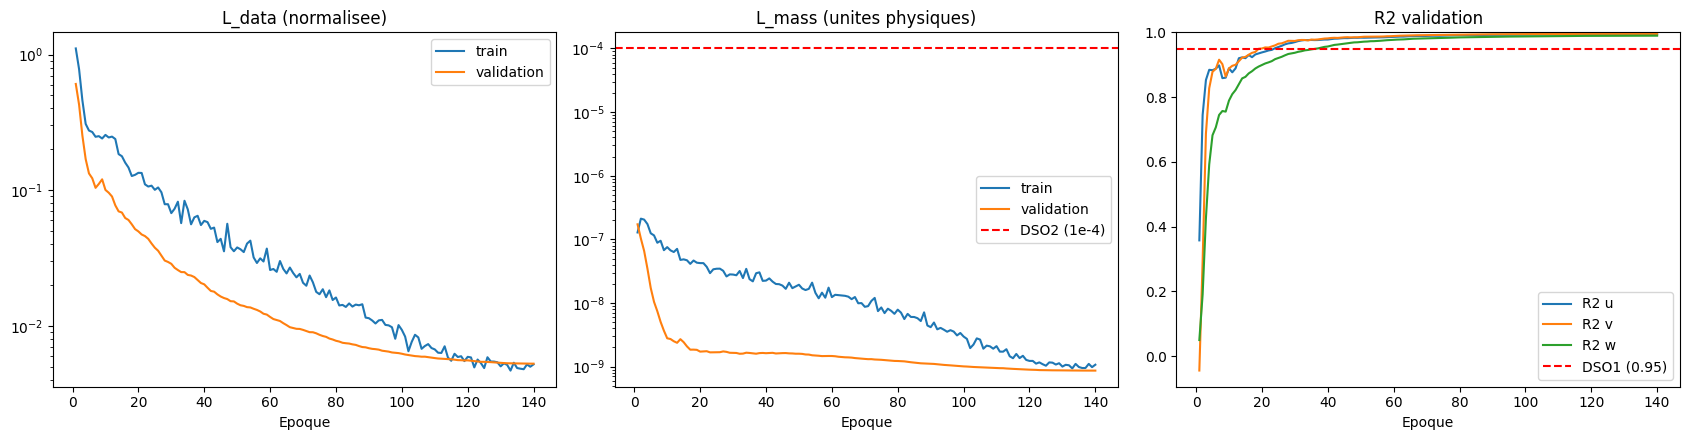

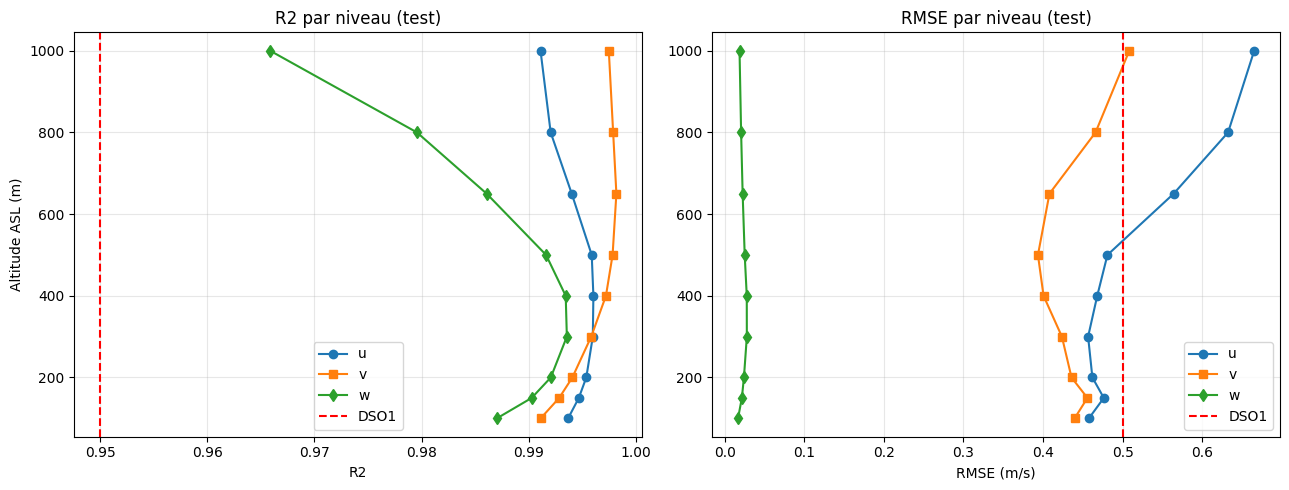

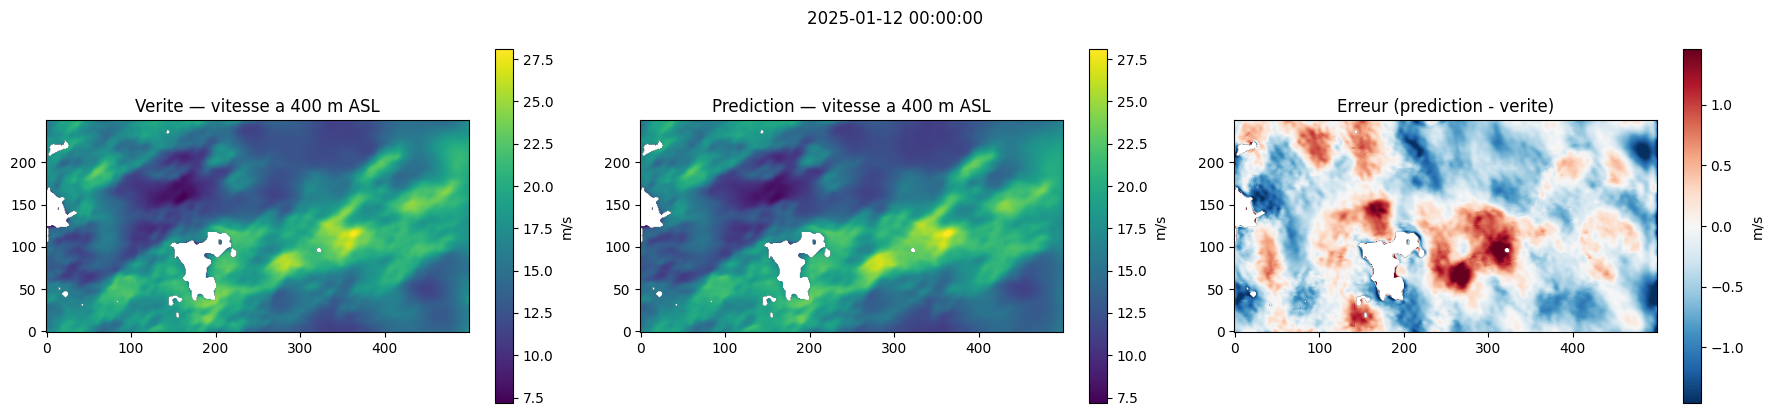

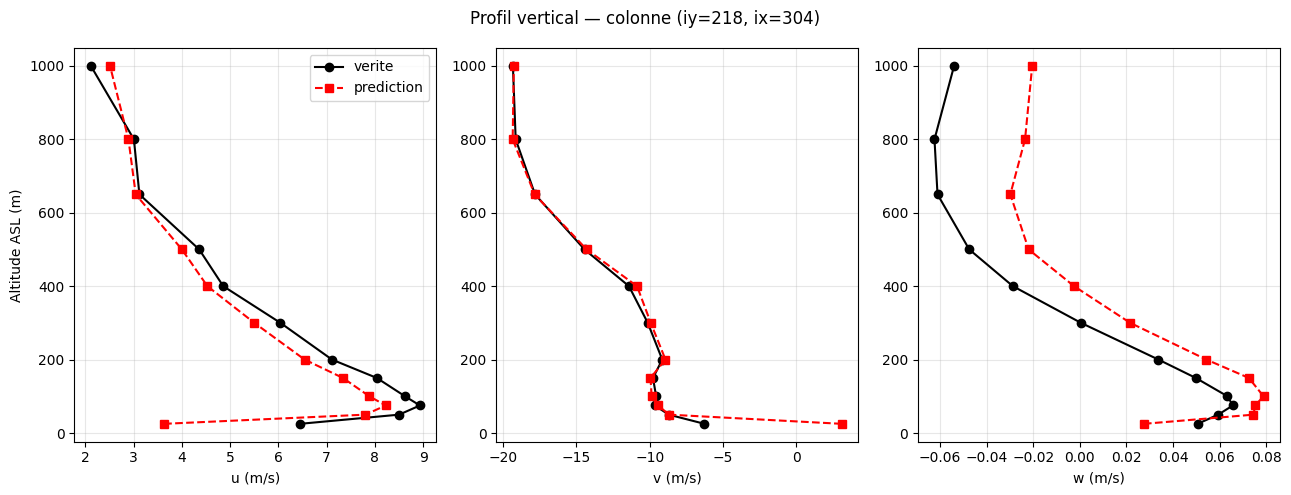

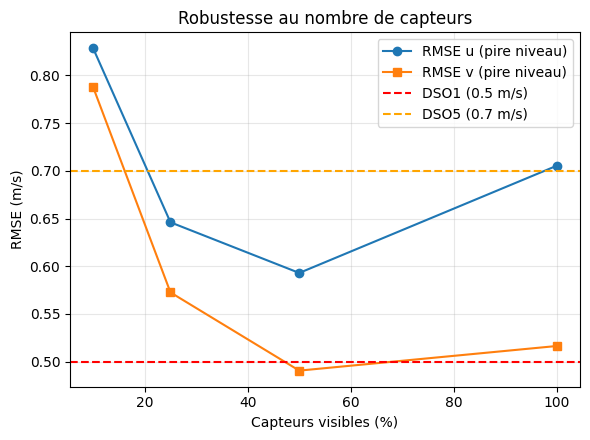

Figures -> /content/drive/MyDrive/aneo_fno3d_runs/v7/figures
BLOC 11 OK


In [29]:
# BLOC 11 — Figures
import matplotlib
if TEST_MODE:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

FIG = RUN_DIR / "figures"
hist = pd.DataFrame([{"epoch": h["epoch"] + 1, "train_data": h["train"]["data"],
                      "val_data": h["val"]["data"], "train_mass": h["train"]["mass"],
                      "val_mass": h["val"]["mass"], "r2_u": h["val_r2_u"], "r2_v": h["val_r2_v"],
                      "r2_w": h["val_r2_w"]} for h in history])

# 1. Courbes d'apprentissage
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].semilogy(hist["epoch"], hist["train_data"], label="train")
ax[0].semilogy(hist["epoch"], hist["val_data"], label="validation")
ax[0].set_title("L_data (normalisee)"); ax[0].set_xlabel("Epoque"); ax[0].legend()
ax[1].semilogy(hist["epoch"], hist["train_mass"], label="train")
ax[1].semilogy(hist["epoch"], hist["val_mass"], label="validation")
ax[1].axhline(1e-4, color="red", ls="--", label="DSO2 (1e-4)")
ax[1].set_title("L_mass (unites physiques)"); ax[1].set_xlabel("Epoque"); ax[1].legend()
for c in "uvw":
    ax[2].plot(hist["epoch"], hist[f"r2_{c}"], label=f"R2 {c}")
ax[2].axhline(0.95, color="red", ls="--", label="DSO1 (0.95)")
ax[2].set_ylim(max(-0.5, hist[["r2_u", "r2_v", "r2_w"]].values.min() - 0.05), 1.0)
ax[2].set_title("R2 validation"); ax[2].set_xlabel("Epoque"); ax[2].legend()
fig.tight_layout(); fig.savefig(FIG / "01_apprentissage.png", dpi=150); plt.show()

# 2. R2 et RMSE par niveau (test, metriques globales)
lv = LEVELS[LEVELS["couverture"] >= MIN_LEVEL_COVER]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c, mk in zip("uvw", "osd"):
    ax[0].plot(lv[f"r2_{c}"].clip(lower=-1), lv["z_m"], marker=mk, label=c)
    ax[1].plot(lv[f"rmse_{c}"], lv["z_m"], marker=mk, label=c)
ax[0].axvline(DSO1_R2, color="red", ls="--", label="DSO1"); ax[0].set_xlabel("R2"); ax[0].set_ylabel("Altitude ASL (m)")
ax[1].axvline(DSO1_RMSE, color="red", ls="--", label="DSO1"); ax[1].set_xlabel("RMSE (m/s)")
ax[0].set_title("R2 par niveau (test)"); ax[1].set_title("RMSE par niveau (test)")
for a_ in ax:
    a_.legend(); a_.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "02_niveaux.png", dpi=150); plt.show()

# 3. Cartes verite / prediction / erreur a 100 m et profil vertical d'une colonne
s_raw, sensor, tfeat, y, j = test_ds[0]
with torch.no_grad():
    pred = model(assemble_input(s_raw[None].to(device), sensor[None].to(device), tfeat[None].to(device)))
u, v, w = [a[0].float().cpu().numpy() for a in denorm(pred.float())]
yt = y.numpy()
# niveau le plus bas couvrant au moins 90 % du domaine (sinon le relief masque la carte)
k100 = int(next((k for k in range(NZ) if VALID[k].mean() >= 0.9), NZ - 1))
vm = VALID[k100]
spd_t = np.where(vm, np.hypot(yt[0, k100], yt[1, k100]), np.nan)
spd_p = np.where(vm, np.hypot(u[k100], v[k100]), np.nan)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
lim = (np.nanmin(spd_t), np.nanmax(spd_t))
for a, data, title in ((ax[0], spd_t, "Verite"), (ax[1], spd_p, "Prediction")):
    im = a.imshow(data, origin="lower", cmap="viridis", vmin=lim[0], vmax=lim[1])
    a.set_title(f"{title} — vitesse a {int(Z_LEVELS[k100])} m ASL"); plt.colorbar(im, ax=a, label="m/s")
err = spd_p - spd_t
emax = np.nanpercentile(np.abs(err), 99)
im = ax[2].imshow(err, origin="lower", cmap="RdBu_r", vmin=-emax, vmax=emax)
ax[2].set_title("Erreur (prediction - verite)"); plt.colorbar(im, ax=ax[2], label="m/s")
fig.suptitle(STAMP_OF[te_s[0]]); fig.tight_layout(); fig.savefig(FIG / "03_cartes_vitesse.png", dpi=150); plt.show()

jj, ii = np.unravel_index(np.argmax(VALID.sum(axis=0)), (NY, NX))
col = VALID[:, jj, ii]
fig, ax = plt.subplots(1, 3, figsize=(13, 5))
for a, c, name in zip(ax, range(3), "uvw"):
    a.plot(yt[c, col, jj, ii], Z_LEVELS[col], "k-o", label="verite")
    a.plot([u, v, w][c][col, jj, ii], Z_LEVELS[col], "r--s", label="prediction")
    a.set_xlabel(f"{name} (m/s)"); a.grid(alpha=0.3)
ax[0].set_ylabel("Altitude ASL (m)"); ax[0].legend()
fig.suptitle(f"Profil vertical — colonne (iy={jj}, ix={ii})")
fig.tight_layout(); fig.savefig(FIG / "04_profil_colonne.png", dpi=150); plt.show()

# 4. Robustesse au nombre de capteurs
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(robust["capteurs_visibles"] * 100, robust["rmse_u_max"], marker="o", label="RMSE u (pire niveau)")
ax.plot(robust["capteurs_visibles"] * 100, robust["rmse_v_max"], marker="s", label="RMSE v (pire niveau)")
ax.axhline(DSO1_RMSE, color="red", ls="--", label="DSO1 (0.5 m/s)")
ax.axhline(DSO5_RMSE, color="orange", ls="--", label="DSO5 (0.7 m/s)")
ax.set_xlabel("Capteurs visibles (%)"); ax.set_ylabel("RMSE (m/s)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Robustesse au nombre de capteurs")
fig.tight_layout(); fig.savefig(FIG / "05_robustesse.png", dpi=150); plt.show()
print("Figures ->", FIG)
print("BLOC 11 OK")

In [32]:
model = _model_single   # restore the normal model after interrupting BLOC 10c
print(type(model).__name__)   # should print: PCFNO3D

PCFNO3D


## BLOC 12 — Reconstruction 3D d'un instant

Modele utilise : best_dso_v7.pt
Instant 2025-01-12 00:00:00 | capteurs utilises : 125,000 | reconstruction en 109 ms
Sauvegarde : recon_004_000000_3d.npz et recon_004_000000_3d.csv (849,184 noeuds) -> /content/drive/MyDrive/aneo_fno3d_runs/v7/reconstructions
Niveau (m) |  RMSE u   RMSE v   RMSE w  | R2 vitesse
       25  |   2.052    9.315   0.0197 | -11899.2080
       50  |   0.534    0.677   0.0193 |   0.8817
       75  |   0.625    0.482   0.0211 |   0.8816
      100  |   0.531    0.479   0.0208 |   0.9071
      150  |   0.483    0.390   0.0255 |   0.9284
      200  |   0.444    0.426   0.0284 |   0.9417
      300  |   0.392    0.425   0.0326 |   0.9581
      400  |   0.415    0.445   0.0367 |   0.9849
      500  |   0.378    0.379   0.0366 |   0.9884
      650  |   0.560    0.449   0.0333 |   0.9689
      800  |   0.597    0.344   0.0313 |   0.9096
     1000  |   1.335    0.464   0.0277 |   0.7671


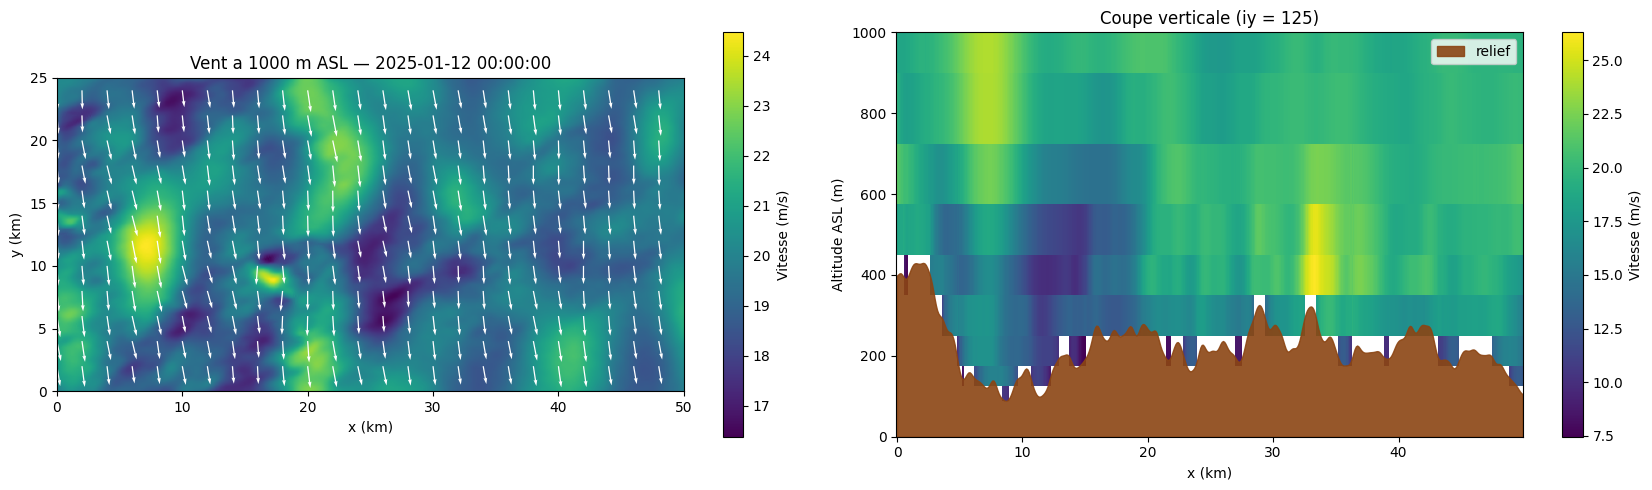

BLOC 12 OK


In [41]:
# BLOC 12 — Reconstruction 3D d'un instant
# Deux sources possibles :
#   A) un instant deja en cache (ex. un jour de test) : RECON_STEM = "004_120000"
#   B) un nouveau fichier de mesures de surface (memes colonnes que le dataset) : RECON_CSV = Path(...)
# Sorties (dans RUN_DIR/reconstructions/) :
#   <nom>_3d.npz  : u, v, w, vitesse, direction (NZ, NY, NX), NaN sous le terrain, niveaux, coordonnees
#   <nom>_3d.csv  : un noeud 3D par ligne (point_id, altitude, u, v, w, vitesse, direction)
#   figures       : carte a l'altitude choisie + coupe verticale
import matplotlib.pyplot as plt

RECON_STEM = None            # ex. "004_120000" ; None = premier instant du test
RECON_CSV = None             # ex. Path("/content/drive/MyDrive/mesures/surface_2025-06-14_1200.csv")
RECON_KEEP = 1.0             # fraction de capteurs utilises (1.0 = tous les capteurs disponibles)
MAP_ALTITUDE = 1000.0         # altitude ASL de la carte (m), ex. hauteur de moyeu d'eolienne
SECTION_ROW = NY // 2        # ligne (iy) de la coupe verticale

if "amp_dtype" not in globals():                       # si le BLOC 9 n'a pas ete execute
    amp_dtype = torch.bfloat16 if device.type == "cuda" else torch.float32
    use_amp = device.type == "cuda"

RECON_DIR = RUN_DIR / "reconstructions"
RECON_DIR.mkdir(parents=True, exist_ok=True)

_ckpt_recon = next((p for p in (RUN_DIR / "best_dso_v7.pt", RUN_DIR / "best.pt")
                    if p.exists()))
ck = torch.load(_ckpt_recon, map_location=device, weights_only=False)
print("Modele utilise :", _ckpt_recon.name)
model.load_state_dict(ck["model"])
model.eval()

def surface_from_csv(path):
    """Mesures de surface d'un seul instant -> (S (8, NY, NX), heure, jour de l'annee, timestamp)."""
    cols = ["point_id", "timestamp_utc", "mask_i_obs"] + SURF_VARS
    df = pd.read_csv(path, usecols=cols)
    df = df[df["point_id"] < NODE_ID_START]
    stamp = pd.Timestamp(df["timestamp_utc"].iloc[0])
    df = df[df["timestamp_utc"] == df["timestamp_utc"].iloc[0]]
    S = np.zeros((8, NY_S * NX_S), dtype=np.float32)
    flat = PID_TO_SURF[df["point_id"].values]
    for ci, var in enumerate(SURF_VARS):
        S[ci, flat] = df[var].values
    S[7, flat] = df["mask_i_obs"].values
    S = pool_surface(S)
    hour = stamp.hour + stamp.minute / 60 + stamp.second / 3600
    return S, hour, stamp.dayofyear, str(stamp)

# 1. Chargement de l'instant
Y_true = None
if RECON_CSV is not None:
    S, hour, doy, stamp = surface_from_csv(RECON_CSV)
    name = f"recon_{pd.Timestamp(stamp).strftime('%Y%m%d_%H%M%S')}"
else:
    stem = RECON_STEM or te_s[0]
    row = INDEX[INDEX["stem"] == stem].iloc[0]
    S = np.load(CACHE_DIR / f"{stem}_S.npy")
    Y_true = np.load(CACHE_DIR / f"{stem}_Y.npy")
    hour, doy, stamp = row["hour"], row["doy"], row["timestamp"]
    name = f"recon_{stem}"

rng = np.random.default_rng(0)
sensor = (S[7] > 0.5) & (rng.random(S[7].shape) < RECON_KEEP)
tfeat = time_geo_features(S, sensor, hour, doy)

# 2. Inference
s_t = torch.from_numpy(S[:N_SURF])[None].to(device)
m_t = torch.from_numpy(sensor.astype(np.float32))[None].to(device)
t_t = torch.from_numpy(tfeat)[None].to(device)
t0 = time.perf_counter()
with torch.no_grad():
    with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
        pred = model(assemble_input(s_t, m_t, t_t))
    u, v, w = [a[0].float().cpu().numpy() for a in denorm(pred.float())]
if device.type == "cuda":
    torch.cuda.synchronize()
t_rec = time.perf_counter() - t0

u = np.where(VALID, u, np.nan)
v = np.where(VALID, v, np.nan)
w = np.where(VALID, w, np.nan)
speed = np.hypot(u, v)
direction = (270.0 - np.degrees(np.arctan2(v, u))) % 360.0     # convention meteo (d'ou vient le vent)
print(f"Instant {stamp} | capteurs utilises : {int(sensor.sum()):,} | reconstruction en {t_rec * 1000:.0f} ms")

# 3. Interpolation a une altitude quelconque (ASL)
def field_at_altitude(field, z):
    """Interpolation lineaire entre niveaux ; NaN sous le terrain ou hors [25, 1000] m."""
    if z < Z_LEVELS[0] or z > Z_LEVELS[-1]:
        raise ValueError(f"Altitude hors domaine [{Z_LEVELS[0]:.0f}, {Z_LEVELS[-1]:.0f}] m")
    k = int(np.clip(np.searchsorted(Z_LEVELS, z) - 1, 0, NZ - 2))
    a = (z - Z_LEVELS[k]) / (Z_LEVELS[k + 1] - Z_LEVELS[k])
    out = (1 - a) * field[k] + a * field[k + 1]
    return np.where(z > zt, out, np.nan)

# 4. Sauvegarde
x_m = np.arange(NX) * DX
y_m = np.arange(NY) * DY
np.savez_compressed(RECON_DIR / f"{name}_3d.npz", u=u.astype(np.float32), v=v.astype(np.float32),
                    w=w.astype(np.float32), speed=speed.astype(np.float32),
                    direction=direction.astype(np.float32), z_levels=Z_LEVELS, x_m=x_m, y_m=y_m,
                    z_terrain=zt.astype(np.float32), timestamp=stamp)

node_ok = NODE_FLAT >= 0
node_pid = np.nonzero(node_ok)[0] + NODE_ID_START
node_flat = NODE_FLAT[node_ok]
kk, jj, ii = np.unravel_index(node_flat, (NZ, NY, NX))
out = pd.DataFrame({
    "point_id": node_pid, "timestamp_utc": stamp, "ix": ii * STRIDE, "iy": jj * STRIDE,
    "z_asl_m": Z_LEVELS[kk], "z_agl_m": np.round(Z_LEVELS[kk] - zt[jj, ii], 2),
    "wind_u_m_s": np.round(u[kk, jj, ii], 3), "wind_v_m_s": np.round(v[kk, jj, ii], 3),
    "wind_w_m_s": np.round(w[kk, jj, ii], 4), "wind_speed_m_s": np.round(speed[kk, jj, ii], 3),
    "wind_direction_deg": np.round(direction[kk, jj, ii], 1),
})
out.to_csv(RECON_DIR / f"{name}_3d.csv", index=False)
print(f"Sauvegarde : {name}_3d.npz et {name}_3d.csv ({len(out):,} noeuds) -> {RECON_DIR}")

# 5. Comparaison a la verite (si l'instant vient du dataset)
if Y_true is not None:
    print("Niveau (m) |  RMSE u   RMSE v   RMSE w  | R2 vitesse")
    for k in range(NZ):
        m = VALID[k]
        if m.sum() < 10:
            continue
        e = [np.sqrt(np.mean((p[k][m] - Y_true[c, k][m]) ** 2)) for c, p in enumerate((u, v, w))]
        st = np.hypot(Y_true[0, k][m], Y_true[1, k][m])
        r2 = 1 - np.sum((speed[k][m] - st) ** 2) / (np.sum((st - st.mean()) ** 2) + 1e-12)
        print(f"  {Z_LEVELS[k]:7.0f}  | {e[0]:7.3f}  {e[1]:7.3f}  {e[2]:7.4f} | {r2:8.4f}")

# 6. Figures : carte a MAP_ALTITUDE et coupe verticale
spd_map = field_at_altitude(speed, MAP_ALTITUDE)
u_map = field_at_altitude(u, MAP_ALTITUDE)
v_map = field_at_altitude(v, MAP_ALTITUDE)
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
im = ax[0].imshow(spd_map, origin="lower", cmap="viridis", extent=[0, NX * DX / 1000, 0, NY * DY / 1000])
step = max(NX // 25, 1)
Xq, Yq = np.meshgrid(x_m[::step] / 1000, y_m[::step] / 1000)
ax[0].quiver(Xq, Yq, u_map[::step, ::step], v_map[::step, ::step], color="white", scale=None, width=0.002)
ax[0].set_title(f"Vent a {MAP_ALTITUDE:.0f} m ASL — {stamp}")
ax[0].set_xlabel("x (km)"); ax[0].set_ylabel("y (km)")
plt.colorbar(im, ax=ax[0], label="Vitesse (m/s)")

sec = speed[:, SECTION_ROW, :]
im = ax[1].pcolormesh(x_m / 1000, Z_LEVELS, sec, cmap="viridis", shading="nearest")
ax[1].fill_between(x_m / 1000, 0, zt[SECTION_ROW], color="saddlebrown", alpha=0.9, label="relief")
ax[1].set_ylim(0, Z_LEVELS[-1])
ax[1].set_title(f"Coupe verticale (iy = {SECTION_ROW})")
ax[1].set_xlabel("x (km)"); ax[1].set_ylabel("Altitude ASL (m)"); ax[1].legend(loc="upper right")
plt.colorbar(im, ax=ax[1], label="Vitesse (m/s)")
fig.tight_layout()
fig.savefig(RECON_DIR / f"{name}_carte_coupe.png", dpi=150)
plt.show()
print("BLOC 12 OK")

In [40]:
for f in ("best_dso_v7.pt", "best.pt", "norm_stats.json",
          "reconstructions/recon_004_000000_3d.npz", "reconstructions/recon_004_000000_3d.csv"):
    p_ = RUN_DIR / f
    print(f"{f:45s}", f"{p_.stat().st_size/1e6:.1f} MB" if p_.exists() else "MANQUANT")

best_dso_v7.pt                                1813.0 MB
best.pt                                       1813.0 MB
norm_stats.json                               0.0 MB
reconstructions/recon_004_000000_3d.npz       14.9 MB
reconstructions/recon_004_000000_3d.csv       69.7 MB


In [34]:
import os, shutil
from google.colab import drive
LOCAL = Path("/content/run_local_v7")
checks = [(RUN_DIR / "best_dso_v7.pt", None),
          (RUN_DIR / "best.pt", LOCAL / "best.pt"),
          (RUN_DIR / "norm_stats.json", None)]
for dst, src in checks:
    ok = dst.exists() and dst.stat().st_size > 0
    same = src is None or (src.exists() and ok and src.stat().st_size == dst.stat().st_size)
    print(f"{dst.name:18s} Drive: {'OK' if ok else 'MANQUANT'} ({dst.stat().st_size/1e9 if ok else 0:.2f} GB)"
          + ("" if src is None else f" | identique au local : {'oui' if same else 'NON'}"))
    if src is not None and src.exists() and not same:
        shutil.copy2(src, dst); print("   -> recopie depuis le disque local")
drive.flush_and_unmount()   # force the end of all uploads to Drive
print("Drive synchronise. Tu peux fermer la session.")

best_dso_v7.pt     Drive: OK (1.81 GB)
best.pt            Drive: OK (1.81 GB) | identique au local : oui
norm_stats.json    Drive: OK (0.00 GB)
Drive synchronise. Tu peux fermer la session.


In [38]:
import os, shutil
from google.colab import drive
if not os.path.ismount("/content/drive"):
    if os.path.exists("/content/drive"):
        shutil.move("/content/drive", "/content/drive_leftover_local")   # local leftover, not your Drive
    drive.mount("/content/drive")
for f in ("best_dso_v7.pt", "best.pt", "norm_stats.json"):
    p_ = RUN_DIR / f
    print(f"{f:18s}", f"{p_.stat().st_size/1e9:.2f} GB" if p_.exists() else "MANQUANT")

Mounted at /content/drive
best_dso_v7.pt     1.81 GB
best.pt            1.81 GB
norm_stats.json    0.00 GB
